In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import itertools
import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, describe, mode, fisher_exact
import scipy as sp
import scipy.stats as stats
# from scipy.spatial.distance import jaccard, euclidean, cosine
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import pairwise_distances
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.decomposition import NMF, non_negative_factorization
from collections import Counter
from scipy.stats import hypergeom
from scipy.stats.mstats import gmean
from scipy.cluster import hierarchy
import squarify
try:
    import piplite
    await piplite.install(['ipywidgets'])
except ImportError:
    pass
import ipywidgets as widgets

today = date.today()

In [2]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    print(mode(data, keepdims=True))
    return fig

Load data

In [3]:
datadir = '/home/ctrader/region_similarity/data/rank_based/'
regions_f = datadir + 'hg38.25kb.maxMean.CT20230118.sorted.bed'

DHS_NMF_f = datadir + 'regions_25kb_CT20230210.DHS.factornormNMF.factorsums.hdf5'
epi_sums_f = datadir + 'regions_25kb_CT20230209.epilogos.statesums.hdf5'

In [4]:
f = open(regions_f, 'r')
regions = []
for line in f.readlines():
    r = line.strip().split('\t')
    regions.append(r)
f.close()
regions = np.array(regions)

In [6]:
def print_coords(i):
    c = regions[i]
    return c[0] + ':' + c[1] + '-' + c[2]


def region_percentile(arr):
    # rank each region
    ranked_regions = rankdata(arr, axis=0)

    # find the number of regions with 0 values for each component
    comp_num_zero = len(arr) - np.count_nonzero(arr, axis=0)

    # adjusting/resetting ranks
    ranked_regions = ranked_regions - comp_num_zero
    ranked_regions = np.where(ranked_regions < 0, 0, ranked_regions)
    
    percentile = ranked_regions / np.max(ranked_regions, axis=0)

    return percentile

In [7]:
DHSalpha2paper_order = np.array([8, 3, 5, 1, 4, 15, 9, 6, 2, 12, 13, 11, 0, 10, 7, 14])
epialpha2paper_order = np.array([10, 12, 14, 13, 15, 16, 3, 4, 0, 1, 5, 17, 6, 11, 2, 8, 9, 7])

DHS_hdf5 = h5py.File(DHS_NMF_f, 'r')
DHS_factors = np.char.decode(DHS_hdf5['factors'][:])[DHSalpha2paper_order]
print(DHS_factors)
DHS_NMFsum = DHS_hdf5['factor_sums'][:][:, DHSalpha2paper_order]
DHS_hdf5.close()

DHS_NMFsum_total = np.sum(DHS_NMFsum, axis=1)
DHS_NMFenrich = DHS_NMFsum / DHS_NMFsum_total.reshape(-1, 1)
DHS_NMFenrich = np.where(np.isnan(DHS_NMFenrich), 0, DHS_NMFenrich)



epi_hdf5 = h5py.File(epi_sums_f, 'r')
epi_sum = epi_hdf5['state_sums'][:][:, epialpha2paper_order]
epi_factors = np.char.decode(epi_hdf5['factors'][:])[epialpha2paper_order]
print(epi_factors)
epi_hdf5.close()
epi_sum = np.where(epi_sum < 0, 0, epi_sum)

DHS_color = np.array(['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', 
                      '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3'])
epi_color = np.array(['#ff0000', '#ff4500', '#ff4500', '#ff4500', '#008000', '#006400', '#c2e105', '#c2e105',
                      '#ffc34d', '#ffc34d', '#ffff00', '#66cdaa', '#8a91d0', '#cd5c5c', '#bdb76b', '#808080', 
                      '#c0c0c0', '#ffffff'])

['Placental_trophoblast' 'Lymphoid' 'Myeloid_erythroid' 'Cardiac'
 'Musculoskeletal' 'Vascular_endothelial' 'Primitive_embryonic' 'Neural'
 'Digestive' 'StromalA' 'StromalB' 'Renal_cancer' 'Cancer_epithelial'
 'Pulmonarydevel' 'Organdevel_renal' 'Tissueinvariant']


/tmp/ipykernel_76458/1637948811.py:11: RuntimeWarning: invalid value encountered in true_divide
  DHS_NMFenrich = DHS_NMFsum / DHS_NMFsum_total.reshape(-1, 1)


['TssA' 'TssFlnk' 'TssFlnkU' 'TssFlnkD' 'Tx' 'TxWk' 'EnhG1' 'EnhG2'
 'EnhA1' 'EnhA2' 'EnhWk' 'ZNF_Rpts' 'Het' 'TssBiv' 'EnhBiv' 'ReprPC'
 'ReprPCWk' 'Quies']


Percentiles and Joining

In [8]:
DHS_NMFenrich_per = region_percentile(DHS_NMFenrich)
DHS_NMFsum_per = region_percentile(DHS_NMFsum)
DHS_per = (DHS_NMFenrich_per + DHS_NMFsum_per) / 2
epi_per = region_percentile(epi_sum)

In [9]:
percents = np.hstack((DHS_per, epi_per))
factor_order = np.append(DHS_factors, epi_factors)
metric_order = np.append(np.array(['DHS signal'] * len(DHS_factors)),
                         np.array(['chromatin states'] * len(epi_factors)))
colors = np.append(DHS_color, epi_color)

In [10]:
# out_percents = np.hstack((regions, np.round(percents, 4)))
# out_header = np.append(
#     np.array(['chrm', 'start', 'end']),
#     joined_factor_order
# )

# out_full = np.vstack((out_header, out_percents))

# outfile = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20230131.DHS_epilogos_factor_percentiles.bed'
# np.savetxt(outfile, 
#            out_full, 
#            delimiter='\t', 
#            fmt='%s')

In [11]:
DHS_color_out = []
for i, j in zip(DHS_factors, DHS_color):
    print(i, j)
    DHS_color_out.append([i, j])
    
# outfile = '/home/ctrader/region_similarity/data/rank_based/DHS_component_colors_CT20230131.tsv'
# np.savetxt(outfile, 
#            np.array(DHS_color_out).T, 
#            delimiter='\t', 
#            fmt='%s')

Placental_trophoblast #FFE500
Lymphoid #FE8102
Myeloid_erythroid #FF0000
Cardiac #07AF00
Musculoskeletal #4C7D14
Vascular_endothelial #414613
Primitive_embryonic #05C1D9
Neural #0467FD
Digestive #009588
StromalA #BB2DD4
StromalB #7A00FF
Renal_cancer #4A6876
Cancer_epithelial #08245B
Pulmonarydevel #B9461D
Organdevel_renal #692108
Tissueinvariant #C3C3C3


Bad regions

In [16]:
for i in np.argsort(np.mean(percents, axis=1))[:10]:
    print(i, print_coords(i), np.round(np.mean(percents, axis=1)[i], 4))

30929 chr17:38218338-38247393 0.0207
62674 chr5:99194496-99219496 0.023
8183 chr10:42113752-42138752 0.0237
3860 chr1:148716700-148742818 0.0253
86862 chrX:117808837-117833837 0.0261
28430 chr16:32315479-32340479 0.0264
46731 chr22:16488510-16513510 0.0267
28462 chr16:33520733-33545733 0.0271
45700 chr21:13479479-13504479 0.0271
45704 chr21:13590079-13615079 0.0277


In [18]:
# roi = 62674

Top region for cardiac DHSs and Active Enhancer 2

In [12]:
c = 0
for r in regions:
    if (int(r[2]) - int(r[1])) > 25000:
        c+=1
c

2568

In [29]:
DHS_factors

array(['Placental_trophoblast', 'Lymphoid', 'Myeloid_erythroid',
       'Cardiac', 'Musculoskeletal', 'Vascular_endothelial',
       'Primitive_embryonic', 'Neural', 'Digestive', 'StromalA',
       'StromalB', 'Renal_cancer', 'Cancer_epithelial', 'Pulmonarydevel',
       'Organdevel_renal', 'Tissueinvariant'], dtype='<U21')

In [30]:
epi_factors

array(['TssA', 'TssFlnk', 'TssFlnkU', 'TssFlnkD', 'Tx', 'TxWk', 'EnhG1',
       'EnhG2', 'EnhA1', 'EnhA2', 'EnhWk', 'ZNF_Rpts', 'Het', 'TssBiv',
       'EnhBiv', 'ReprPC', 'ReprPCWk', 'Quies'], dtype='<U8')

In [237]:
target_DHS_ind = np.where(DHS_factors=='Musculoskeletal')[0][0]
target_epi_ind = np.where(epi_factors=='Het')[0][0]
print(target_DHS_ind, target_epi_ind)

4 12


In [238]:
6546000-6571000

-25000

In [239]:
ave_per = (DHS_per[:, target_DHS_ind])
for ind in np.argsort(-ave_per)[:20]:
    print(ind,
          print_coords(ind), '\t', 
          np.round(DHS_per[ind, target_DHS_ind], 4), 
          epi_factors[np.argmax(epi_per[ind])],
          np.round(np.max(epi_per[ind]), 4), 
          np.round(ave_per[ind], 4))

10891 chr10:129262936-129287936 	 0.9972 Het 0.7359 0.9972
27370 chr15:100294595-100319595 	 0.9963 Het 0.9414 0.9963
78066 chr8:92439572-92464572 	 0.9962 Quies 0.7915 0.9962
45462 chr20:58699544-58724544 	 0.996 EnhG1 0.8436 0.996
11501 chr11:15578654-15603654 	 0.9959 Quies 0.4632 0.9959
10879 chr10:128875336-128900336 	 0.9958 Het 0.8825 0.9958
38618 chr2:72409671-72434671 	 0.9954 Het 0.7066 0.9954
55409 chr4:52343834-52368834 	 0.9946 Quies 0.754 0.9946
70082 chr6:159470568-159495568 	 0.9942 ZNF_Rpts 0.6338 0.9942
7949 chr10:31618072-31643072 	 0.994 EnhWk 0.7592 0.994
64910 chr5:171567796-171592796 	 0.9935 Het 0.872 0.9935
40708 chr2:143458831-143483831 	 0.9928 EnhA2 0.9054 0.9928
60901 chr5:39324898-39349898 	 0.9926 Quies 0.5272 0.9926
19285 chr13:22084861-22109861 	 0.9926 EnhA2 0.7727 0.9926
4347 chr1:165009163-165034163 	 0.9925 ZNF_Rpts 0.5662 0.9925
11078 chr11:1916770-1941770 	 0.9924 EnhA2 0.9794 0.9924
10911 chr10:129928536-129953536 	 0.9922 EnhBiv 0.8742 0.9922
45

In [240]:
ave_per = ((DHS_per[:, target_DHS_ind]) + 
           (epi_per[:, target_epi_ind])) / 2
for ind in np.argsort(-ave_per)[:20]:
    print(ind,
          print_coords(ind), '\t', 
          np.round(DHS_per[ind, target_DHS_ind], 4), 
          np.round(epi_per[ind, target_epi_ind], 4), 
          np.round(ave_per[ind], 4))

36303 chr19:56894632-56919632 	 0.9807 0.991 0.9858
61053 chr5:44141898-44166898 	 0.972 0.9871 0.9795
36308 chr19:57046832-57071832 	 0.9658 0.9922 0.979
77976 chr8:89649572-89674572 	 0.9654 0.9867 0.9761
27448 chr16:837200-862200 	 0.973 0.9754 0.9742
45813 chr21:17173682-17198682 	 0.9759 0.971 0.9734
34493 chr18:76084245-76109245 	 0.9882 0.9539 0.9711
75258 chr7:159155108-159180309 	 0.9691 0.9729 0.971
11100 chr11:2629970-2654970 	 0.9573 0.9827 0.97
27370 chr15:100294595-100319595 	 0.9963 0.9414 0.9689
65148 chr5:179297599-179322599 	 0.9878 0.9457 0.9667
59808 chr5:4021686-4046887 	 0.9742 0.9586 0.9664
76280 chr8:33015282-33040282 	 0.9842 0.9477 0.9659
72404 chr7:67541613-67566613 	 0.9799 0.9507 0.9653
24720 chr14:101347263-101372263 	 0.9648 0.9652 0.965
8024 chr10:34078472-34103472 	 0.953 0.974 0.9635
43656 chr2:238455759-238480759 	 0.9534 0.9714 0.9624
24716 chr14:101202263-101227263 	 0.9505 0.9741 0.9623
32452 chr18:4526800-4551800 	 0.9561 0.9647 0.9604
75074 chr7:

ROI

In [473]:
roi = 73238 # StromalB and EnhA2 targeted
roi = 49858 # Musculoskeletal and EnhWk
roi = 36303 # Musculoskeletal and ZNF_Rpts

roi = 75190 # Primitive_embryonic and EnhBiv
target_DHS_ind = np.where(DHS_factors=='Primitive_embryonic')[0][0]
target_epi_ind = np.where(epi_factors=='EnhBiv')[0][0]
target_factors = np.append(target_DHS_ind, target_epi_ind+16)

# roi = 34493 # Musculoskeletal and Het
# target_DHS_ind = np.where(DHS_factors=='Musculoskeletal')[0][0]
# target_epi_ind = np.where(epi_factors=='Het')[0][0]
# target_factors = np.append(target_DHS_ind, target_epi_ind+16)

# roi = 45463 # Musculoskeletal and ReprPCWk
# target_DHS_ind = np.where(DHS_factors=='Musculoskeletal')[0][0]
# target_epi_ind = np.where(epi_factors=='ReprPCWk')[0][0]
# target_factors = np.append(target_DHS_ind, target_epi_ind+16)

# roi = 22461 # Neural and ReprPC
# target_DHS_ind = np.where(DHS_factors=='Neural')[0][0]
# target_epi_ind = np.where(epi_factors=='ReprPC')[0][0]
# target_factors = np.append(target_DHS_ind, target_epi_ind+16)

roi = 59157 # Cardiac and ReprPC
target_DHS_ind = np.where(DHS_factors=='Cardiac')[0][0]
target_epi_ind = np.where(epi_factors=='ReprPC')[0][0]
target_factors = np.append(target_DHS_ind, target_epi_ind+16)

print(target_factors)

[ 3 31]


Find regions based on what you want to see

In [474]:
dropdown_options = []
for name, i in zip(factor_order, range(len(factor_order))):
    dropdown_options.append((name, i))

In [475]:
factor_threshod = np.zeros(len(factor_order))

In [476]:
factor_dropdown = widgets.Dropdown(
    options=dropdown_options,
    description='Factor:',
)
factor_dropdown

Dropdown(description='Factor:', options=(('Placental_trophoblast', 0), ('Lymphoid', 1), ('Myeloid_erythroid', …

In [477]:
threshold_slider = widgets.BoundedFloatText(
    value=factor_threshod[factor_dropdown.value] * 100,
    min=0,
    max=100.0,
    step=0.1,
    description='Threshold %',
    disabled=False
)
threshold_slider

BoundedFloatText(value=0.0, description='Threshold %', step=0.1)

In [478]:
#setting threshold values
factor_threshod[factor_dropdown.value] = threshold_slider.value / 100
print(factor_threshod)

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [479]:
filter_inds = np.where(
    np.count_nonzero(
        percents >= factor_threshod, axis=1
    ) == len(factor_order)
)[0]
print('%s regions available' %(len(filter_inds)))

88036 regions available


In [480]:
# for i in filter_inds:
#     print(i, print_coords(i))

Convolution

In [481]:
# # all regions at once
# t = time.time()
# conv_top = []
# sim_top = []
# regions_top = []
# for i in range(len(percents)):
#     if (i % 10000) == 0:
#         print(i)
#     i_percents = percents[i]
#     i_conv_all = percents * i_percents
#     i_sim_all = 1 - np.prod(1 - i_conv_all, axis=1)
#     i_top_regions = np.argsort(-i_sim_all)[:101]
#     i_top_regions = i_top_regions[i_top_regions != i][:100]
#     i_conv_top = i_conv_all[i_top_regions]
#     i_sim_top = i_sim_all[i_top_regions]
#     conv_top.append(i_conv_top)
#     sim_top.append(i_sim_top)
#     regions_top.append(i_top_regions)
# print(time.time()-t)

# conv_top = np.array(conv_top)
# sim_top = np.array(sim_top)
# regions_top = np.array(regions_top)

# out_path = '/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20230131.DHSsignalZ.epilogosmaxstateperbin.ranked.percentile.convolution.fusionsim.hdf5'
# out_f = h5py.File(out_path, 'w')
# out_f.create_dataset('convolution', data=conv_top)
# out_f.create_dataset('similarity', data=sim_top)
# out_f.create_dataset('regions', data=regions_top)
# out_f.create_dataset('factor_order', data=np.char.encode(joined_factor_order))
# out_f.create_dataset('metric_order', data=np.char.encode(joined_metric_order))
# out_f.create_dataset('ranks', data=joined_ranks)
# out_f.create_dataset('max_ranks', data=joined_max_ranks)
# out_f.create_dataset('percentiles', data=percents)
# out_f.close()

In [482]:
# print(regions_top.shape)
# print(sim_top.shape)
# print(conv_top.shape)

In [483]:
roi_percents = percents[roi]
print(roi_percents)

[0.43273653 0.3782752  0.55604621 0.99568012 0.74621954 0.356916
 0.93560404 0.91396854 0.70213792 0.5674926  0.78847281 0.18804763
 0.15146076 0.60809231 0.95335056 0.44105236 0.55470914 0.63871579
 0.49551651 0.6586735  0.         0.         0.         0.64462744
 0.         0.52693599 0.         0.         0.         0.99936767
 0.99868992 0.97206869 0.         0.        ]


In [484]:
t = time.time()
roi_conv_all = percents * roi_percents
print(time.time()-t)

0.017828941345214844


Fusion

In [485]:
t = time.time()
roi_sim_all = 1 - np.prod(1 - roi_conv_all, axis=1)
print(time.time()-t)

0.0173952579498291


In [486]:
top_regions = np.argsort(-roi_sim_all)[:101]
top_regions = np.append(roi, top_regions[top_regions!=roi][:100])

In [487]:
# similarity_out = []

In [488]:
# similarity_out.append(top_regions)

In [489]:
# similarity_out = np.array(similarity_out)
# similarity_out.shape

In [490]:
# outfile = '/home/ctrader/region_similarity/data/rank_based/convolution_fusion_similarity_hits_query_top100_CT20230131.tsv'
# np.savetxt(outfile, 
#            similarity_out, 
#            delimiter='\t', 
#            fmt='%s')

Score distribution

DescribeResult(nobs=88036, minmax=(0.0, 0.9999999999999974), mean=0.9853005205938613, variance=0.004613257183995291, skewness=-11.422320068688316, kurtosis=151.72464664565152)
ModeResult(mode=array([0.]), count=array([280]))


Text(0.5, 1.0, 'Score Distribution for ROI 59157')

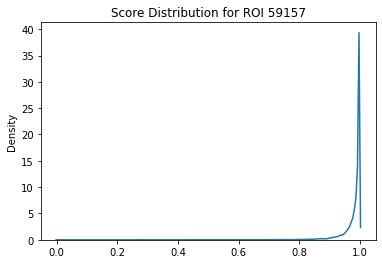

In [491]:
fig = kde_wrapper(roi_sim_all)
plt.title('Score Distribution for ROI ' + str(roi))

In [492]:
print(len(roi_sim_all[roi_sim_all>0]))
print(len(roi_sim_all[roi_sim_all>0.9]))
print(len(roi_sim_all[roi_sim_all>0.99]))
print(len(roi_sim_all[roi_sim_all>0.999]))
print(len(roi_sim_all[roi_sim_all>0.9999]))
print(len(roi_sim_all[roi_sim_all>0.99999]))
print(len(roi_sim_all[roi_sim_all>0.999999]))
print(len(roi_sim_all[roi_sim_all==1]))

87756
85799
69623
47549
30128
18948
11229
0


In [493]:
# inds_over_thresh = np.where(percents[top_regions[0]] > 0.9)[0]
# print('Query:',
#       top_regions[0],
#       len(inds_over_thresh),
#       factor_order[inds_over_thresh],
#       percents[top_regions[0]][inds_over_thresh],
#       print_coords(top_regions[0])
#      )
# print()

# for region in top_regions[1:11]:
#     inds_over_thresh = np.where(roi_conv_all[region] > 0.9)[0]
#     print(region,
#           np.round(roi_sim_all[region], 9),
#           len(inds_over_thresh),
#           factor_order[inds_over_thresh],
#           percents[region][inds_over_thresh],
#           np.round(np.max(roi_conv_all[region]), 4),
#           print_coords(region)
#          )
#     print()

In [494]:
inds_over_thresh = np.where(percents[top_regions[0]] > 0.9)[0]
print('Query:',
      top_regions[0],
      len(inds_over_thresh),
      factor_order[inds_over_thresh],
      percents[top_regions[0]][inds_over_thresh],
      print_coords(top_regions[0])
     )
print()

for region in top_regions[1:11]:
    inds_over_thresh = np.where(percents[region] > 0.9)[0]
    print(region,
          np.round(roi_sim_all[region], 9),
          len(inds_over_thresh),
          factor_order[inds_over_thresh],
#           percents[region][inds_over_thresh],
#           np.round(np.max(roi_conv_all[region]), 4),
          print_coords(region)
         )
    print()

Query: 59157 7 ['Cardiac' 'Primitive_embryonic' 'Neural' 'Organdevel_renal' 'TssBiv'
 'EnhBiv' 'ReprPC'] [0.99568012 0.93560404 0.91396854 0.95335056 0.99936767 0.99868992
 0.97206869] chr4:173514849-173539849

25407 1.0 7 ['Cardiac' 'Organdevel_renal' 'TssA' 'TssFlnk' 'TssBiv' 'EnhBiv' 'ReprPC'] chr15:37090599-37115599

31649 1.0 6 ['Primitive_embryonic' 'Pulmonarydevel' 'Organdevel_renal' 'EnhG2'
 'TssBiv' 'EnhBiv'] chr17:61393639-61418639

41584 1.0 6 ['Lymphoid' 'Primitive_embryonic' 'Organdevel_renal' 'TssBiv' 'EnhBiv'
 'ReprPC'] chr2:172082072-172107072

62498 1.0 6 ['Neural' 'Organdevel_renal' 'TssFlnk' 'TssBiv' 'EnhBiv' 'ReprPC'] chr5:93578294-93603294

71253 1.0 6 ['Musculoskeletal' 'Primitive_embryonic' 'Organdevel_renal' 'TssBiv'
 'EnhBiv' 'ReprPC'] chr7:27178581-27203581

27247 1.0 9 ['Vascular_endothelial' 'Organdevel_renal' 'TssA' 'TssFlnk' 'TssFlnkU'
 'EnhG2' 'EnhA2' 'TssBiv' 'EnhBiv'] chr15:96332571-96357571

32207 1.0 7 ['Lymphoid' 'Primitive_embryonic' 'Neural' 'Organ

70
199
556
1161
5820
80224


Text(0.5, 1.0, 'Number of factors filtering')

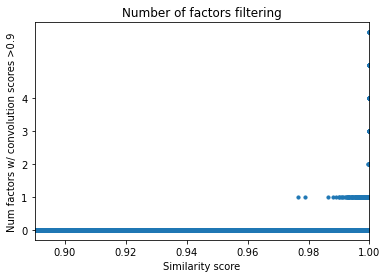

In [495]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(roi_sim_all, np.count_nonzero(roi_conv_all > 0.9, axis=1), s=10)

plt.xlim([0.89, 1])
plt.yticks([0, 1, 2, 3, 4])

plt.xlabel('Similarity score')
plt.ylabel('Num factors w/ convolution scores >0.9')
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==5))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==4))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==3))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==2))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==1))
print(np.count_nonzero(np.count_nonzero(roi_conv_all > 0.9, axis=1)==0))
plt.title('Number of factors filtering')

In [496]:
factor_order

array(['Placental_trophoblast', 'Lymphoid', 'Myeloid_erythroid',
       'Cardiac', 'Musculoskeletal', 'Vascular_endothelial',
       'Primitive_embryonic', 'Neural', 'Digestive', 'StromalA',
       'StromalB', 'Renal_cancer', 'Cancer_epithelial', 'Pulmonarydevel',
       'Organdevel_renal', 'Tissueinvariant', 'TssA', 'TssFlnk',
       'TssFlnkU', 'TssFlnkD', 'Tx', 'TxWk', 'EnhG1', 'EnhG2', 'EnhA1',
       'EnhA2', 'EnhWk', 'ZNF_Rpts', 'Het', 'TssBiv', 'EnhBiv', 'ReprPC',
       'ReprPCWk', 'Quies'], dtype='<U21')

In [497]:
# top_inds = top_regions[:100]

# top_r = regions[top_inds]
# top_factors_per_r = []
# for ind in top_inds:
#     factors_over_thresh = np.where(roi_conv_all[ind] > 0.9)[0]
#     top_factors_per_r.append('/'.join(factor_order[factors_over_thresh]))
# top_factors_per_r = np.array(top_factors_per_r)
# top_r = np.hstack((top_r, top_factors_per_r.reshape(-1, 1)))

In [498]:
top_inds = top_regions[:100]

top_r = regions[top_inds]
top_factors_per_r = []
factors_over_thresh_arr = np.array([], dtype=int)
regions_with_all_targets = np.array([], dtype=int)
for ind in top_inds:
    factors_over_thresh = np.where(percents[ind] > 0.9)[0]
    factors_over_thresh_arr = np.append(factors_over_thresh_arr, factors_over_thresh)
    if (len(factors_over_thresh[np.isin(factors_over_thresh, target_factors)]) == 
        len(target_factors)):
        regions_with_all_targets = np.append(regions_with_all_targets, ind)
    top_factors_per_r.append('/'.join(factor_order[factors_over_thresh]))
top_factors_per_r = np.array(top_factors_per_r)
top_r = np.hstack((top_r, top_factors_per_r.reshape(-1, 1)))

on_target_per = (len(factors_over_thresh_arr[np.isin(factors_over_thresh_arr, target_factors)]) / 
                 len(factors_over_thresh_arr))
print('roi = %s' %roi)
print('On target factors = %s' %factor_order[target_factors])
print('On target fraction = %s' %np.round(on_target_per, 4))
print('Fraction of regions with all target factors = %s' %(len(regions_with_all_targets) / len(top_inds)))

roi = 59157
On target factors = ['Cardiac' 'ReprPC']
On target fraction = 0.156
Fraction of regions with all target factors = 0.16


In [499]:
def roiurl_fusion(top_regions):
    today = date.today()
    query_region = '_'.join(top_regions[0, :3])
    roiurl_name = 'convolution_fusion_similarities_region_' + query_region + '_25kb_CT' + today.strftime("%Y%m%d") + '.bed'
    bed_path_name = os.path.join('/home/ctrader/public_html/', roiurl_name)
    np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
    link_path_epi = 'https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roiurl_name
    link_path_index = 'https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roiurl_name
    link_path_both = 'https://index.altius.org:3000/?application=viewer&mode=cf&&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roiurl_name
    print(link_path_epi)
    print(link_path_index)
    print(link_path_both)
    return # link_path_epi, link_path_index

In [500]:
roiurl_fusion(top_r)

https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fconvolution_fusion_similarities_region_chr4_173514849_173539849_25kb_CT20230213.bed
https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fconvolution_fusion_similarities_region_chr4_173514849_173539849_25kb_CT20230213.bed
https://index.altius.org:3000/?application=viewer&mode=cf&&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fconvolution_fusion_similarities_region_chr4_173514849_173539849_25kb_CT20230213.bed


Text(0.5, 1.0, 'Max convolution score filtering')

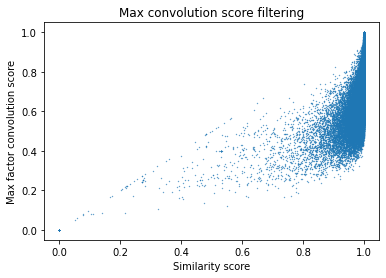

In [501]:
fig = plt.figure()
fig.patch.set_facecolor('white')

plt.scatter(roi_sim_all, np.max(roi_conv_all, axis=1), s=0.1)

# plt.xlim([0.9, 1])
# plt.ylim([0.5, 1])
plt.xlabel('Similarity score')
plt.ylabel('Max factor convolution score')
plt.title('Max convolution score filtering')

**Narrate**

In [119]:
metriccolors = {
    'DHS signal': '\033[94m',
    'TF': '\033[92m',
    'chromatin states': '\033[91m',
    'STANDARD': '\033[0m',
    'BOLD': '\033[1m',
    'UNDERLINE': '\033[4m'
}

epi_conversion_dict = {
    'EnhA1': 'active enhancer 1',
    'EnhA2': 'active enhancer 2',
    'EnhBiv': 'bivalent enhancer',
    'EnhG1': 'genic enhancer 1',
    'EnhG2': 'genic enhancer 2',
    'EnhWk': 'weak enhancer',
    'Het': 'heterochromatin',
    'Quies': 'quiescent',
    'ReprPC': 'repressed polycomb',
    'ReprPCWk': 'weak repressed polycomb',
    'TssA': 'active TSS',
    'TssBiv': 'bivalent TSS',
    'TssFlnk': 'flanking TSS',
    'TssFlnkD': 'downstream flanking TSS',
    'TssFlnkU': 'upstream flanking TSS',
    'Tx': 'strong transcription',
    'TxWk': 'weak transcription',
    'ZNF_Rpts': 'ZNF genes + repeats'
}

DHS_conversion_dict = {
    'Cancer_epithelial': 'cancer/epithelial',
    'Cardiac': 'cardiac',
    'Digestive': 'digestive',
    'Lymphoid': 'lymphoid',
    'Musculoskeletal': 'musculoskeletal',
    'Myeloid_erythroid': 'myeloid/erythroid',
    'Neural': 'neural',
    'Organdevel_renal': 'organ development/renal',
    'Placental_trophoblast': 'placental/trophoblast',
    'Primitive_embryonic': 'primitive/embryonic',
    'Pulmonarydevel': 'pulmonary development',
    'Renal_cancer': 'renal/cancer',
    'StromalA': 'stromal A',
    'StromalB': 'stromal B',
    'Tissueinvariant': 'tissue invariant',
    'Vascular_endothelial': 'vascular/endothelial'
}

def narrate_sim(top_regions, roi_conv_top, joined_factor_order, joined_metric_order, thresh=0.9):
    query = top_regions[0]
    hits = top_regions[1:]
    roi_conv_hits = roi_conv_top[1:]
    sentences = []
    for region, roi_conv_hit in zip(hits, roi_conv_hits):
        sim_factors = np.where(roi_conv_hit > thresh)[0]
        if len(sim_factors) > 0:
            sentence = 'This region is highly similar to the query region in terms of '
            sim_factor_names = factor_order[sim_factors]
            sim_metric_names = metric_order[sim_factors]
            m_sections = []
            for m in np.unique(sim_metric_names):
                m_inds = np.where(sim_metric_names == m)[0]
                m_factors = sim_factor_names[m_inds]
                factors_joined = metriccolors[m]
                if len(m_factors) > 2:
                    factors_joined += ', '.join(m_factors[:-1])
                    factors_joined += ', and ' + m_factors[-1]
                elif len(m_factors) == 2:
                    factors_joined += ' and '.join(m_factors)
                else:
                    factors_joined += m_factors[0]
                    
                factors_joined += ' ' + m + metriccolors['STANDARD']
                m_sections.append(factors_joined)
            if len(m_sections) > 2:
                metrics_joined = ', '.join(m_sections[:-1])
                metrics_joined += ', and ' + m_sections[-1]
            if len(m_sections) == 2:
                metrics_joined = ' and '.join(m_sections)
            else:
                metrics_joined = m_sections[0]
                
            sentence += metrics_joined + '.'
        
        else:
            sentence = ''
        sentences.append(sentence)
    return sentences

sentences = narrate_sim(top_regions, roi_conv_all[top_regions], factor_order, metric_order)

for s in sentences:
    print(s)

This region is highly similar to the query region in terms of TssFlnkU, EnhG2, EnhA1, and EnhA2 chromatin states.
This region is highly similar to the query region in terms of TssFlnkU, EnhG1, EnhG2, EnhA1, and EnhA2 chromatin states.
This region is highly similar to the query region in terms of TssFlnkU, EnhG1, EnhG2, EnhA1, and EnhA2 chromatin states.
This region is highly similar to the query region in terms of TssFlnkU, EnhG1, EnhG2, and EnhA1 chromatin states.
This region is highly similar to the query region in terms of TssFlnkU, EnhG1, EnhG2, and EnhBiv chromatin states.
This region is highly similar to the query region in terms of StromalB DHS signal and TssFlnkU, EnhG2, EnhA1, EnhA2, and EnhBiv chromatin states.
This region is highly similar to the query region in terms of TssFlnkU, EnhG1, EnhG2, EnhA1, EnhA2, and EnhBiv chromatin states.
This region is highly similar to the query region in terms of TssFlnkU, EnhG1, EnhG2, and EnhA1 chromatin states.
This region is highly simi

**Tree plots**

Text(0.5, 0.91, 'Query Region Percentiles')

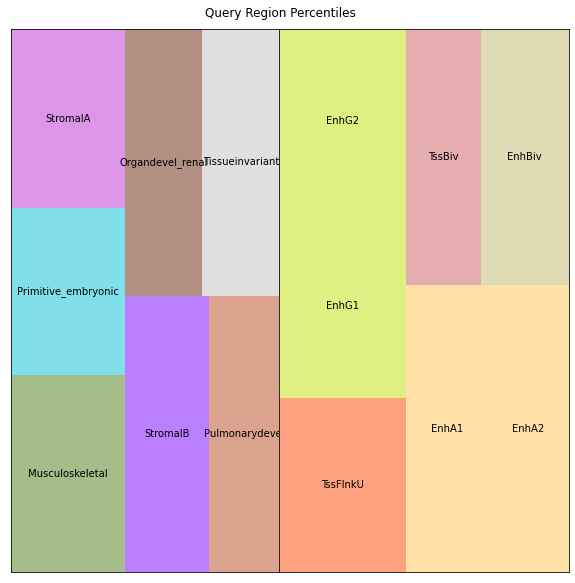

In [120]:
#query
factor_sums = percents[roi]
nonzero_inds = np.where(factor_sums>0.8)[0]
nonzero_factors = factor_sums[nonzero_inds]
nonzero_names = factor_order[nonzero_inds]
nonzero_color = colors[nonzero_inds]
nonzero_metrics = metric_order[nonzero_inds]

plot_ratios = []
for metric in np.unique(nonzero_metrics):
    metric_inds = np.where(nonzero_metrics==metric)[0]
    plot_ratios.append(np.sum(nonzero_factors[metric_inds]))

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10,10), gridspec_kw={'width_ratios': plot_ratios})
fig.patch.set_facecolor('white')
fig.subplots_adjust(wspace=0)

axes = axes.ravel()

for ax, metric in zip(axes, np.unique(nonzero_metrics)):
    metric_inds = np.where(nonzero_metrics==metric)[0]
    squarify.plot(sizes=nonzero_factors[metric_inds], 
                  label=nonzero_names[metric_inds], 
                  alpha=0.5, 
                  color=nonzero_color[metric_inds],
                  ax=ax)
    ax.set_xticks([])
    ax.set_yticks([])
    
fig.suptitle('Query Region Percentiles', y=0.91)

Text(0.5, 0.91, 'Similar Region 1 Percentiles')

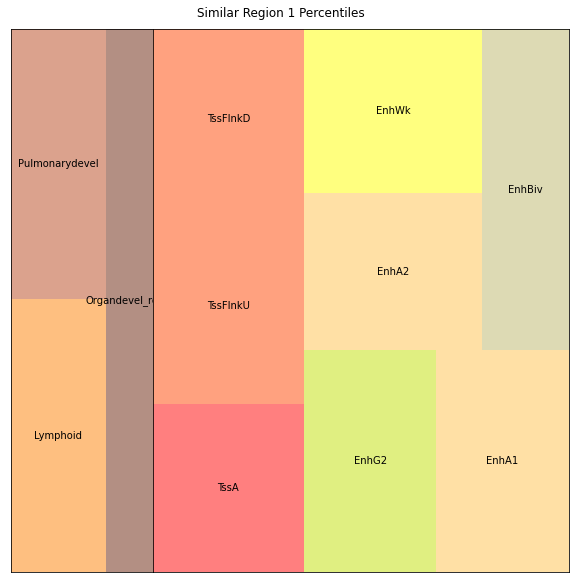

In [121]:
#hits

hit = 1
factor_sums = percents[top_regions[hit]]
nonzero_inds = np.where(factor_sums>0.85)[0]
nonzero_factors = factor_sums[nonzero_inds]
nonzero_names = factor_order[nonzero_inds]
nonzero_color = colors[nonzero_inds]
nonzero_metrics = metric_order[nonzero_inds]

plot_ratios = []
for metric in np.unique(nonzero_metrics):
    metric_inds = np.where(nonzero_metrics==metric)[0]
    plot_ratios.append(np.sum(nonzero_factors[metric_inds]))

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10,10), gridspec_kw={'width_ratios': plot_ratios})
fig.patch.set_facecolor('white')
fig.subplots_adjust(wspace=0)

axes = axes.ravel()

for ax, metric in zip(axes, np.unique(nonzero_metrics)):
    metric_inds = np.where(nonzero_metrics==metric)[0]
    squarify.plot(sizes=nonzero_factors[metric_inds], 
                  label=nonzero_names[metric_inds], 
                  alpha=0.5, 
                  color=nonzero_color[metric_inds],
                  ax=ax)
    ax.set_xticks([])
    ax.set_yticks([])
    
fig.suptitle('Similar Region %s Percentiles' %(hit), y=0.91)

Text(0.5, 0.91, 'Similar Regions 1-10 Convolution Scores')

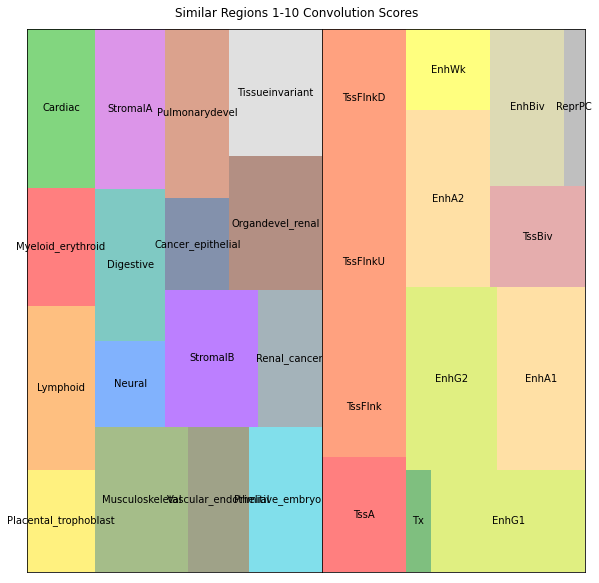

In [122]:
#top hits
start_hit = 1
end_hit = 10
factor_sums = np.sum(roi_conv_all[top_regions[start_hit:end_hit+1]], axis=0)
nonzero_inds = np.where(factor_sums>0.9)[0]
nonzero_factors = factor_sums[nonzero_inds]
nonzero_names = factor_order[nonzero_inds]
nonzero_color = colors[nonzero_inds]
nonzero_metrics = metric_order[nonzero_inds]


plot_ratios = []
for metric in np.unique(nonzero_metrics):
    metric_inds = np.where(nonzero_metrics==metric)[0]
    plot_ratios.append(np.sum(nonzero_factors[metric_inds]))

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10,10), gridspec_kw={'width_ratios': plot_ratios})
fig.patch.set_facecolor('white')
fig.subplots_adjust(wspace=0)

axes = axes.ravel()

for ax, metric in zip(axes, np.unique(nonzero_metrics)):
    metric_inds = np.where(nonzero_metrics==metric)[0]
    squarify.plot(sizes=nonzero_factors[metric_inds], 
                  label=nonzero_names[metric_inds], 
                  alpha=0.5, 
                  color=nonzero_color[metric_inds],
                  ax=ax)
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle('Similar Regions %s-%s Convolution Scores' %(start_hit, end_hit), y=0.91)